<a href="https://colab.research.google.com/github/plnmrnk/market-activity-anomaly-detector/blob/main/market_activity_anomaly_monitor_v0.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Market Activity Anomaly Monitor - V0

##1 - Project Overview

- Objectif: Identifier des journées avec mouvements de prix ou volumes inhabituels
- Données: Actions cotées, données historiques quotidiennes
- Outils: Python, pandas

In [1]:
!pip install yfinance

In [2]:
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')

##2 - Data Collection

In [3]:
stocks = yf.download(['MC.PA', 'AIR.PA', 'BNP.PA'], start='2025-10-01', end='2026-10-02')

# MC.PA = LVMH, AIR.PA = AirBus, BNP.PA = BNP Paribas

stocks.head()

/tmp/ipykernel_11495/2164875808.py:1: FutureWarning: YF.download() has changed argument auto_adjust default to True
  stocks = yf.download(['MC.PA', 'AIR.PA', 'BNP.PA'], start='2025-10-01', end='2026-10-02')
[*********************100%***********************]  3 of 3 completed


Price            Close                               High             \
Ticker          AIR.PA     BNP.PA       MC.PA      AIR.PA     BNP.PA   
Date                                                                   
2025-10-01  195.468170  73.631546  511.180389  196.096558  73.687945   
2025-10-02  198.384277  72.870224  529.618103  199.218847  74.035694   
2025-10-03  199.857071  73.311981  539.568420  200.937105  74.129694   
2025-10-06  197.451523  70.962242  527.179199  199.169773  72.456675   
2025-10-07  198.777023  70.144524  546.299683  200.004345  71.169015   

Price                          Low                               Open  \
Ticker           MC.PA      AIR.PA     BNP.PA       MC.PA      AIR.PA   
Date                                                                    
2025-10-01  516.838481  191.815659  71.197216  508.936671  193.583006   
2025-10-02  531.276465  196.017998  72.804431  520.252929  196.371467   
2025-10-03  539.568420  198.875214  72.221697  526.398697  199.071582   
2025-10-06  537.910085  196.469665  68.809877  524.545243  196.911498   
2025-10-07  549.421407  196.420572  70.012939  531.666655  197.304237   

Price                               Volume                   
Ticker         BNP.PA       MC.PA   AIR.PA   BNP.PA   MC.PA  
Date                                                         
2025-10-01  72.578866  510.497503   961217  2153316  381637  
2025-10-02  73.913510  520.740697   926298  1954767  561065  
2025-10-03  73.584552  529.618010   809976  1792351  586960  
2025-10-06  72.325090  537.519848  1016212  3901585  600595  
2025-10-07  70.962237  532.642191   576393  2571730  689135

##3 - Data Quality Assessment

The datasetet contains 256 daily trading observations and 5 market variables, covering October 1, 2025 to October 1, 2026.
No missing values were identified in the dataset.
The data is suitable for the inital exploratory analysis.

In [4]:
stocks.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 256 entries, 2025-10-01 to 2026-10-01
Data columns (total 15 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   (Close, AIR.PA)   256 non-null    float64
 1   (Close, BNP.PA)   256 non-null    float64
 2   (Close, MC.PA)    256 non-null    float64
 3   (High, AIR.PA)    256 non-null    float64
 4   (High, BNP.PA)    256 non-null    float64
 5   (High, MC.PA)     256 non-null    float64
 6   (Low, AIR.PA)     256 non-null    float64
 7   (Low, BNP.PA)     256 non-null    float64
 8   (Low, MC.PA)      256 non-null    float64
 9   (Open, AIR.PA)    256 non-null    float64
 10  (Open, BNP.PA)    256 non-null    float64
 11  (Open, MC.PA)     256 non-null    float64
 12  (Volume, AIR.PA)  256 non-null    int64  
 13  (Volume, BNP.PA)  256 non-null    int64  
 14  (Volume, MC.PA)   256 non-null    int64  
dtypes: float64(12), int64(3)
memory usage: 32.0 KB


In [5]:
stocks.describe()

Price        Close                                High              \
Ticker      AIR.PA      BNP.PA       MC.PA      AIR.PA      BNP.PA   
count   256.000000  256.000000  256.000000  256.000000  256.000000   
mean    190.740249   85.633167  513.970578  192.987723   86.476174   
std      14.879344   12.680215   67.965814   14.589834   12.719243   
min     156.292053   61.412880  379.500000  158.157591   62.033215   
25%     177.527309   75.892000  463.529137  179.559998   76.486484   
50%     194.350006   85.549446  492.625000  195.464444   86.381252   
75%     202.713383   97.845829  585.526413  204.528174   98.687786   
max     216.204987  109.163841  641.637329  217.285040  110.150957   

Price                      Low                                Open  \
Ticker       MC.PA      AIR.PA      BNP.PA       MC.PA      AIR.PA   
count   256.000000  256.000000  256.000000  256.000000  256.000000   
mean    520.570114  188.623343   84.680578  508.104997  190.793006   
std      67.741467   15.130545   12.597523   67.115805   14.868131   
min     389.250000  154.563989   61.206109  379.100006  155.369113   
25%     471.319586  174.452041   75.391505  457.895983  177.538490   
50%     497.569760  191.668731   84.590748  485.774994  193.531857   
75%     591.930363  201.047564   96.829680  577.394879  202.538840   
max     643.802043  214.250000  108.815445  633.273720  216.008622   

Price                                 Volume                              
Ticker      BNP.PA       MC.PA        AIR.PA        BNP.PA         MC.PA  
count   256.000000  256.000000  2.560000e+02  2.560000e+02  2.560000e+02  
mean     85.644677  514.329278  1.123277e+06  2.417981e+06  5.105741e+05  
std      12.713793   67.355030  5.141114e+05  1.275580e+06  2.279621e+05  
min      61.422280  387.000000  1.082580e+05  3.080920e+05  5.587800e+04  
25%      75.847353  466.098583  7.941655e+05  1.663706e+06  3.670685e+05  
50%      85.368537  491.977753  1.018110e+06  2.138632e+06  4.783440e+05  
75%      97.594210  583.332239  1.306681e+06  2.824824e+06  5.863960e+05  
max     109.202545  642.818093  3.877479e+06  1.307298e+07  1.701998e+06

##4 - Data Preparation

In [6]:
stocks_clean = stocks.loc[ :, ['Close', 'Volume']]

stocks_clean.head()

Price            Close                          Volume                 
Ticker          AIR.PA     BNP.PA       MC.PA   AIR.PA   BNP.PA   MC.PA
Date                                                                   
2025-10-01  195.468170  73.631546  511.180389   961217  2153316  381637
2025-10-02  198.384277  72.870224  529.618103   926298  1954767  561065
2025-10-03  199.857071  73.311981  539.568420   809976  1792351  586960
2025-10-06  197.451523  70.962242  527.179199  1016212  3901585  600595
2025-10-07  198.777023  70.144524  546.299683   576393  2571730  689135

In [7]:
stocks_clean = (stocks_clean.stack(level = 'Ticker', future_stack = True)).swaplevel('Date', 'Ticker').sort_index()


In [8]:
stocks_clean.info()

<class 'pandas.core.frame.DataFrame'>
MultiIndex: 768 entries, ('AIR.PA', Timestamp('2025-10-01 00:00:00')) to ('MC.PA', Timestamp('2026-10-01 00:00:00'))
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Close   768 non-null    float64
 1   Volume  768 non-null    int64  
dtypes: float64(1), int64(1)
memory usage: 16.4+ KB


##5 - Daily Returns Analysis

In [9]:
stocks_clean['Daily Return'] = stocks_clean.groupby('Ticker')['Close'].pct_change(fill_method=None) * 100
#The Daily Return data sould be read in percentage (ex: 3.606890%, -2,296135%, etc.)

stocks_clean

Price                   Close   Volume  Daily Return
Ticker Date                                         
AIR.PA 2025-10-01  195.468170   961217           NaN
       2025-10-02  198.384277   926298      1.491858
       2025-10-03  199.857071   809976      0.742394
       2025-10-06  197.451523  1016212     -1.203634
       2025-10-07  198.777023   576393      0.671304
...                       ...      ...           ...
MC.PA  2026-09-25  396.850006   508148     -0.062956
       2026-09-28  398.799988   499958      0.491365
       2026-09-29  394.600006   372219     -1.053155
       2026-09-30  390.000000   829329     -1.165739
       2026-10-01  379.500000   773338     -2.692308

[768 rows x 3 columns]

In [10]:
stocks_clean.groupby('Ticker')['Daily Return'].agg(['mean', 'std', 'min', 'max'])

,mean,std,min,max
Ticker,,,,
AIR.PA,-0.003686,1.831115,-6.753046,7.772731
BNP.PA,0.101128,1.776888,-7.731334,7.477308
MC.PA,-0.098700,1.912516,-7.890714,12.218466


##6 -Unusual Trading Activity Detection

In [11]:
mean_return = (stocks_clean.groupby('Ticker')['Daily Return']
               .transform(lambda x: x.shift(1).rolling(60).mean())
               )
std_return = (stocks_clean.groupby('Ticker')['Daily Return']
              .transform(lambda x: x.shift(1).rolling(60).std())
              )
upper_threshold = mean_return + (std_return * 2)
lower_threshold = mean_return - (std_return * 2)

In [12]:
price_anomalies = (stocks_clean
                   .loc[(stocks_clean['Daily Return'] < lower_threshold) | (stocks_clean['Daily Return'] > upper_threshold), :]
                   )

price_anomalies

Price                   Close   Volume  Daily Return
Ticker Date                                         
AIR.PA 2026-01-19  206.582779  1088437     -3.219871
       2026-02-19  183.705521  3076080     -6.753046
       2026-03-19  160.985336  1962764     -3.722842
       2026-03-23  163.381058  2108959      3.405413
       2026-04-01  164.853851  2248144      4.402430
       2026-04-08  172.080322  2385184      7.772731
       2026-04-17  176.223755  1859573      4.482478
       2026-04-29  174.619995  2334773      5.129433
       2026-05-06  188.500000  2670945      5.982233
       2026-07-22  208.300003  2342279      7.040080
BNP.PA 2026-01-09   81.959030  7020926      5.696962
       2026-02-13   84.026810  3943675     -2.391088
       2026-03-02   86.545731  3460803     -3.581159
       2026-03-03   83.002319  4597542     -4.094265
       2026-03-10   83.058723  3027246      3.562645
       2026-03-12   80.643181  3478616     -4.069768
       2026-04-01   80.248421  2811388      5.420427
       2026-04-08   84.571953  5316923      7.477308
       2026-05-06   87.795799  3070460      5.215146
       2026-06-12   93.573151  3251218      5.166409
       2026-07-08   95.102211  2559855     -3.448620
       2026-08-27   97.415176  3464946     -4.786228
       2026-09-18   97.492592  5485737     -2.929278
       2026-10-01   91.540001  3969937     -3.642104
MC.PA  2026-01-16  599.425720   574531     -2.637041
       2026-01-19  573.449280   568048     -4.333555
       2026-01-21  575.810791   401160      2.666676
       2026-01-28  534.091064  1402549     -7.890714
       2026-02-20  545.800110   929807      4.365003
       2026-03-02  512.148865   774130     -4.337431
       2026-03-13  466.099731   845874     -4.303030
       2026-04-08  490.846222   948639      6.854456
       2026-05-06  474.000000   755072      5.111429
       2026-05-11  452.000000   683161     -4.379101
       2026-07-23  453.549988   858456     -4.314349
       2026-09-09  411.250000  1029072     -3.586916

In [13]:
bnpp_test = stocks_clean.loc[('BNP.PA'), :]

bnpp_test = bnpp_test.assign(Mean_Return = mean_return.loc[('BNP.PA'), :],
                 Standard_Deviation = std_return.loc[('BNP.PA'), :],
                 Upper = upper_threshold.loc[('BNP.PA'), :],
                 Lower = lower_threshold.loc[('BNP.PA'), :])

bnpp_test

Price,Close,Volume,Daily Return,Mean_Return,Standard_Deviation,Upper,Lower
Date,,,,,,,
2025-10-01,73.631546,2153316,NaN,NaN,NaN,NaN,NaN
2025-10-02,72.870224,1954767,-1.033962,NaN,NaN,NaN,NaN
2025-10-03,73.311981,1792351,0.606225,NaN,NaN,NaN,NaN
2025-10-06,70.962242,3901585,-3.205123,NaN,NaN,NaN,NaN
2025-10-07,70.144524,2571730,-1.152329,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...
2026-09-25,99.300003,1845774,0.883880,0.000333,1.441681,2.883695,-2.883030
2026-09-28,98.260002,2138699,-1.047332,0.009200,1.445511,2.900222,-2.881822
2026-09-29,97.400002,1677350,-0.875230,-0.023189,1.447075,2.870961,-2.917339


In [14]:
bnpp_test['Mean_Return'].first_valid_index()

Timestamp('2025-12-29 00:00:00')

In [15]:
bnpp_test.iloc[60:62, :]

Price,Close,Volume,Daily Return,Mean_Return,Standard_Deviation,Upper,Lower
Date,,,,,,,
2025-12-24,75.680519,308092,-0.111654,NaN,NaN,NaN,NaN
2025-12-29,75.398560,1514671,-0.372566,0.061632,1.780926,3.623484,-3.500219


In [16]:
upper_threshold.notna().groupby('Ticker').sum()

,Daily Return
Ticker,
AIR.PA,195
BNP.PA,195
MC.PA,195


In [17]:
price_anomalies.groupby('Ticker').size()

,0
Ticker,
AIR.PA,10
BNP.PA,14
MC.PA,12


In [18]:
price_anomalies_frequency = ((price_anomalies.groupby('Ticker').size()) / (upper_threshold.notna().groupby('Ticker').sum())) * 100

price_anomalies_frequency

,0
Ticker,
AIR.PA,5.128205
BNP.PA,7.179487
MC.PA,6.153846


In [19]:
alerts = (price_anomalies.shape[0] / upper_threshold.notna().sum()) * 100

alerts

np.float64(6.153846153846154)

In [20]:
stocks_clean['Average Volume 20D'] = (stocks_clean.groupby('Ticker')['Volume'].transform(lambda x: x.shift(1).rolling(20).mean()))

stocks_clean.loc['BNP.PA']

Price,Close,Volume,Daily Return,Average Volume 20D
Date,,,,
2025-10-01,73.631546,2153316,NaN,NaN
2025-10-02,72.870224,1954767,-1.033962,NaN
2025-10-03,73.311981,1792351,0.606225,NaN
2025-10-06,70.962242,3901585,-3.205123,NaN
2025-10-07,70.144524,2571730,-1.152329,NaN
...,...,...,...,...
2026-09-25,99.300003,1845774,0.883880,2086258.75
2026-09-28,98.260002,2138699,-1.047332,2067151.65
2026-09-29,97.400002,1677350,-0.875230,2001670.50


In [21]:
stocks_clean['Volume Ratio'] = (stocks_clean['Volume'] / stocks_clean['Average Volume 20D'])

stocks_clean

Price                   Close   Volume  Daily Return  Average Volume 20D  \
Ticker Date                                                                
AIR.PA 2025-10-01  195.468170   961217           NaN                 NaN   
       2025-10-02  198.384277   926298      1.491858                 NaN   
       2025-10-03  199.857071   809976      0.742394                 NaN   
       2025-10-06  197.451523  1016212     -1.203634                 NaN   
       2025-10-07  198.777023   576393      0.671304                 NaN   
...                       ...      ...           ...                 ...   
MC.PA  2026-09-25  396.850006   508148     -0.062956           621027.85   
       2026-09-28  398.799988   499958      0.491365           623070.45   
       2026-09-29  394.600006   372219     -1.053155           620705.70   
       2026-09-30  390.000000   829329     -1.165739           618431.55   
       2026-10-01  379.500000   773338     -2.692308           633601.45   

Price              Volume Ratio  
Ticker Date                      
AIR.PA 2025-10-01           NaN  
       2025-10-02           NaN  
       2025-10-03           NaN  
       2025-10-06           NaN  
       2025-10-07           NaN  
...                         ...  
MC.PA  2026-09-25      0.818237  
       2026-09-28      0.802410  
       2026-09-29      0.599671  
       2026-09-30      1.341020  
       2026-10-01      1.220543  

[768 rows x 5 columns]

In [22]:
stocks_clean.groupby('Ticker')['Volume Ratio'].agg('mean')

,Volume Ratio
Ticker,
AIR.PA,1.038464
BNP.PA,0.985603
MC.PA,1.031392


In [23]:
volume_anomalies = stocks_clean.loc[(stocks_clean['Volume Ratio'] > 2), :]

volume_anomalies

Price                   Close   Volume  Daily Return  Average Volume 20D  \
Ticker Date                                                                
AIR.PA 2025-12-01  189.086090  3877479     -5.805821           815393.20   
       2025-12-02  187.043823  2063938     -1.080072           976171.75   
       2025-12-03  194.525574  2159616      3.999999          1048304.15   
       2026-01-27  195.782349  2107630     -1.482213           937769.90   
       2026-02-19  183.705521  3076080     -6.753046          1136846.75   
       2026-03-20  158.000488  3167914     -1.854112          1421749.55   
       2026-05-29  179.699997  3476455      1.125492          1367477.10   
       2026-07-22  208.300003  2342279      7.040080          1015705.25   
       2026-09-18  193.380005  2621206     -1.084396           844766.75   
BNP.PA 2025-12-19   75.755714  6202498      0.448655          2858479.35   
       2026-01-09   81.959030  7020926      5.696962          2316886.40   
       2026-03-20   77.193756  7305963     -2.793227          2720394.45   
       2026-05-29   89.953705  4405488      1.296855          2039334.85   
       2026-06-19   98.305519  5148719      0.474782          2027671.10   
       2026-08-27   97.415176  3464946     -4.786228          1458541.00   
       2026-08-31   99.466835  3448322      0.214514          1547952.40   
       2026-09-18   97.492592  5485737     -2.929278          1837853.30   
MC.PA  2026-01-20  560.854614   775476     -2.196300           332455.15   
       2026-01-28  534.091064  1402549     -7.890714           377924.55   
       2026-03-20  450.602448  1359678     -0.499720           604318.25   
       2026-05-29  473.049988  1701998     -1.642587           533655.10   
       2026-06-19  499.250000  1653923     -1.158188           650960.10   
       2026-07-23  453.549988   858456     -4.314349           418120.30   
       2026-09-09  411.250000  1029072     -3.586916           456288.90   
       2026-09-18  402.799988  1227232     -2.304148           525240.20   

Price              Volume Ratio  
Ticker Date                      
AIR.PA 2025-12-01      4.755349  
       2025-12-02      2.114319  
       2025-12-03      2.060104  
       2026-01-27      2.247492  
       2026-02-19      2.705800  
       2026-03-20      2.228180  
       2026-05-29      2.542240  
       2026-07-22      2.306062  
       2026-09-18      3.102875  
BNP.PA 2025-12-19      2.169859  
       2026-01-09      3.030328  
       2026-03-20      2.685626  
       2026-05-29      2.160257  
       2026-06-19      2.539228  
       2026-08-27      2.375625  
       2026-08-31      2.227667  
       2026-09-18      2.984861  
MC.PA  2026-01-20      2.332573  
       2026-01-28      3.711188  
       2026-03-20      2.249937  
       2026-05-29      3.189322  
       2026-06-19      2.540744  
       2026-07-23      2.053132  
       2026-09-09      2.255308  
       2026-09-18      2.336516

In [24]:
anomalies_dates = price_anomalies.index.intersection(volume_anomalies.index)

anomalies = stocks_clean.loc[anomalies_dates, :]

anomalies

Price                   Close   Volume  Daily Return  Average Volume 20D  \
Ticker Date                                                                
AIR.PA 2026-02-19  183.705521  3076080     -6.753046          1136846.75   
       2026-07-22  208.300003  2342279      7.040080          1015705.25   
BNP.PA 2026-01-09   81.959030  7020926      5.696962          2316886.40   
       2026-08-27   97.415176  3464946     -4.786228          1458541.00   
       2026-09-18   97.492592  5485737     -2.929278          1837853.30   
MC.PA  2026-01-28  534.091064  1402549     -7.890714           377924.55   
       2026-07-23  453.549988   858456     -4.314349           418120.30   
       2026-09-09  411.250000  1029072     -3.586916           456288.90   

Price              Volume Ratio  
Ticker Date                      
AIR.PA 2026-02-19      2.705800  
       2026-07-22      2.306062  
BNP.PA 2026-01-09      3.030328  
       2026-08-27      2.375625  
       2026-09-18      2.984861  
MC.PA  2026-01-28      3.711188  
       2026-07-23      2.053132  
       2026-09-09      2.255308

In [25]:
anomalies_frequency = ((upper_threshold.notna()) & (stocks_clean['Average Volume 20D'].notna())).sum()

anomalies_frequency

np.int64(585)

In [26]:
stocks_analysis = stocks_clean.loc[(stocks_clean['Average Volume 20D'].notna()) & (upper_threshold.notna())]

stocks_analysis.shape

(585, 5)

In [27]:
anomalies_ratio = (anomalies_dates.shape[0] / stocks_analysis.shape[0]) * 100

anomalies_ratio

1.3675213675213675

In [28]:
price_anomalies.groupby('Ticker').size()

,0
Ticker,
AIR.PA,10
BNP.PA,14
MC.PA,12


In [29]:
volume_anomalies.groupby('Ticker').size()

,0
Ticker,
AIR.PA,9
BNP.PA,8
MC.PA,8


In [30]:
anomalies.groupby('Ticker').size()

,0
Ticker,
AIR.PA,2
BNP.PA,3
MC.PA,3


In [31]:
combined_alert_rate = (anomalies.shape[0] / anomalies_frequency) * 100

combined_alert_rate

np.float64(1.3675213675213675)

##7 - Market Anomalies Visualization

In [32]:
def plot_market_anomalies(ticker):
  stocks_data = stocks_clean.loc[ticker]
  if ticker in anomalies.index.get_level_values('Ticker'):
     stocks_alerts = anomalies.loc[ticker]
  else:
     stocks_alerts = stocks_data.iloc[0:0]
  fig, axes = plt.subplots(2, 1, figsize =(12,10))

  sns.lineplot(
      data=stocks_data,
      x=stocks_data.index,
      y='Close',
      color='navy',
      label='Closing Price',
      ax=axes[0])
  sns.scatterplot(
      data=stocks_alerts,
      x=stocks_alerts.index,
      y='Close',
      color='red',
      label='Price & Volume Anomalies',
      s=100,
      ax=axes[0])
  axes[1].bar(
      stocks_data.index,
      stocks_data['Volume'],
      width=3,
      label='Daily Trading Volume')
  sns.lineplot(
      data=stocks_data,
      x=stocks_data.index,
      y='Average Volume 20D',
      color='navy',
      label='20-D Average Volume',
      ax=axes[1])
  sns.scatterplot(
      data=stocks_alerts,
      x=stocks_alerts.index,
      y='Volume',
      color='red',
      s=100,
      label='Price & Volume Anomalies',
      ax=axes[1])

  axes[0].set(
      title=f'{ticker} | Price Anomaly Detection',
      xlabel='Date',
      ylabel='Closing Price (€)'
  )

  axes[1].set(
      title=f'{ticker} | Trading Volume Anomaly Detection',
      xlabel='Date',
      ylabel='Trading Volume (Shares)'
  )

  axes[0].legend()
  axes[1].legend()
  plt.tight_layout()

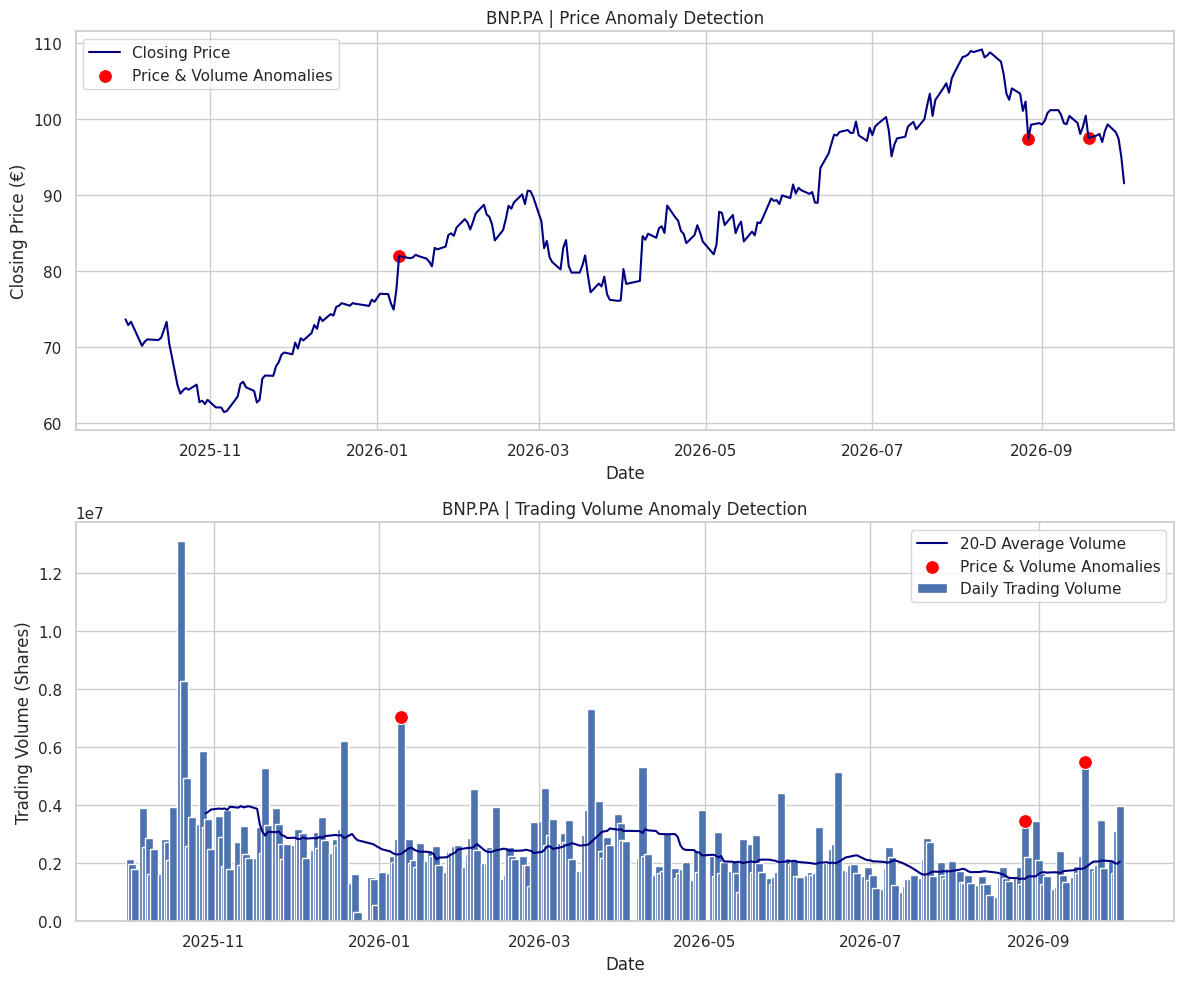

In [33]:
plot_market_anomalies('BNP.PA')

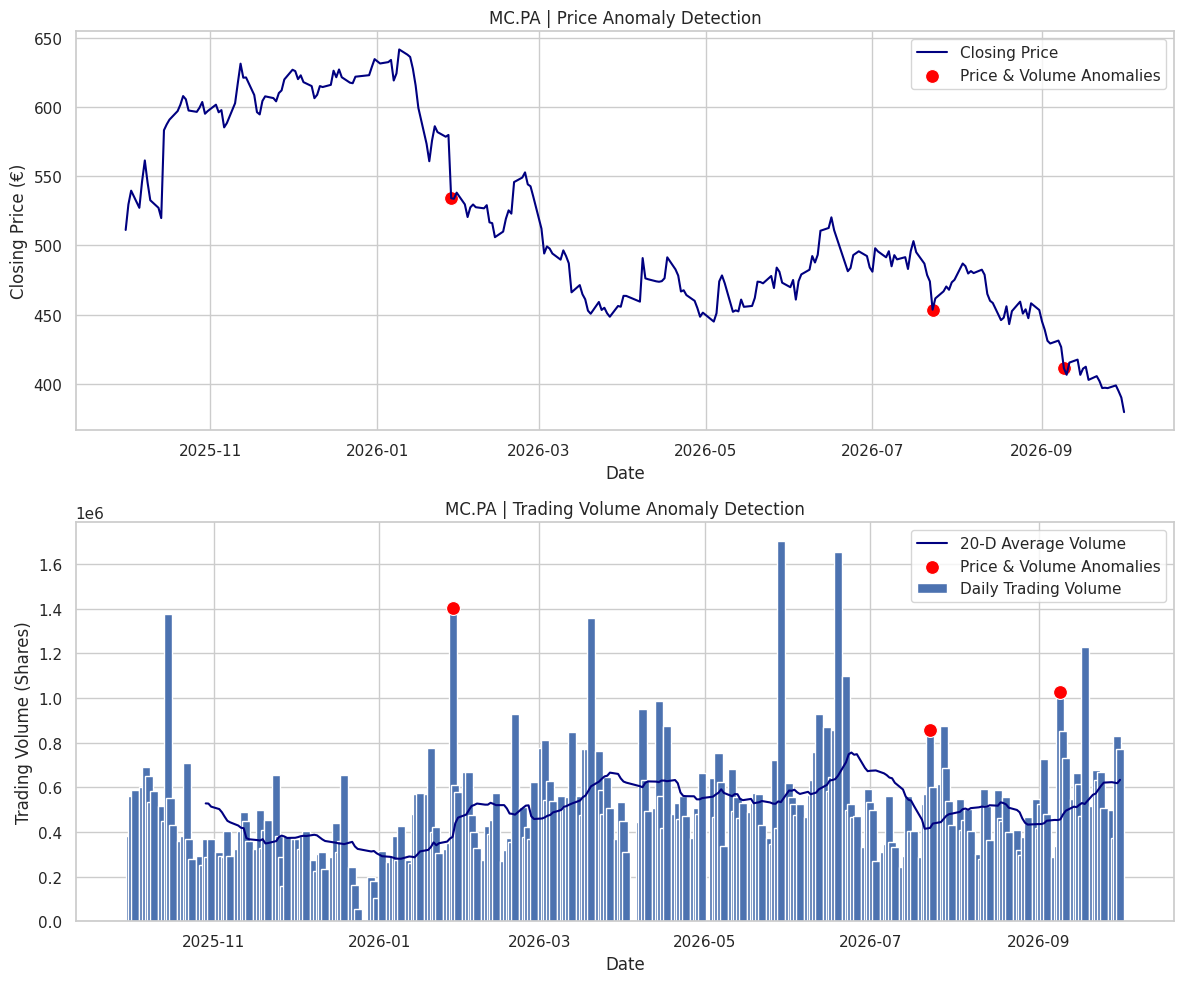

In [34]:
plot_market_anomalies('MC.PA')

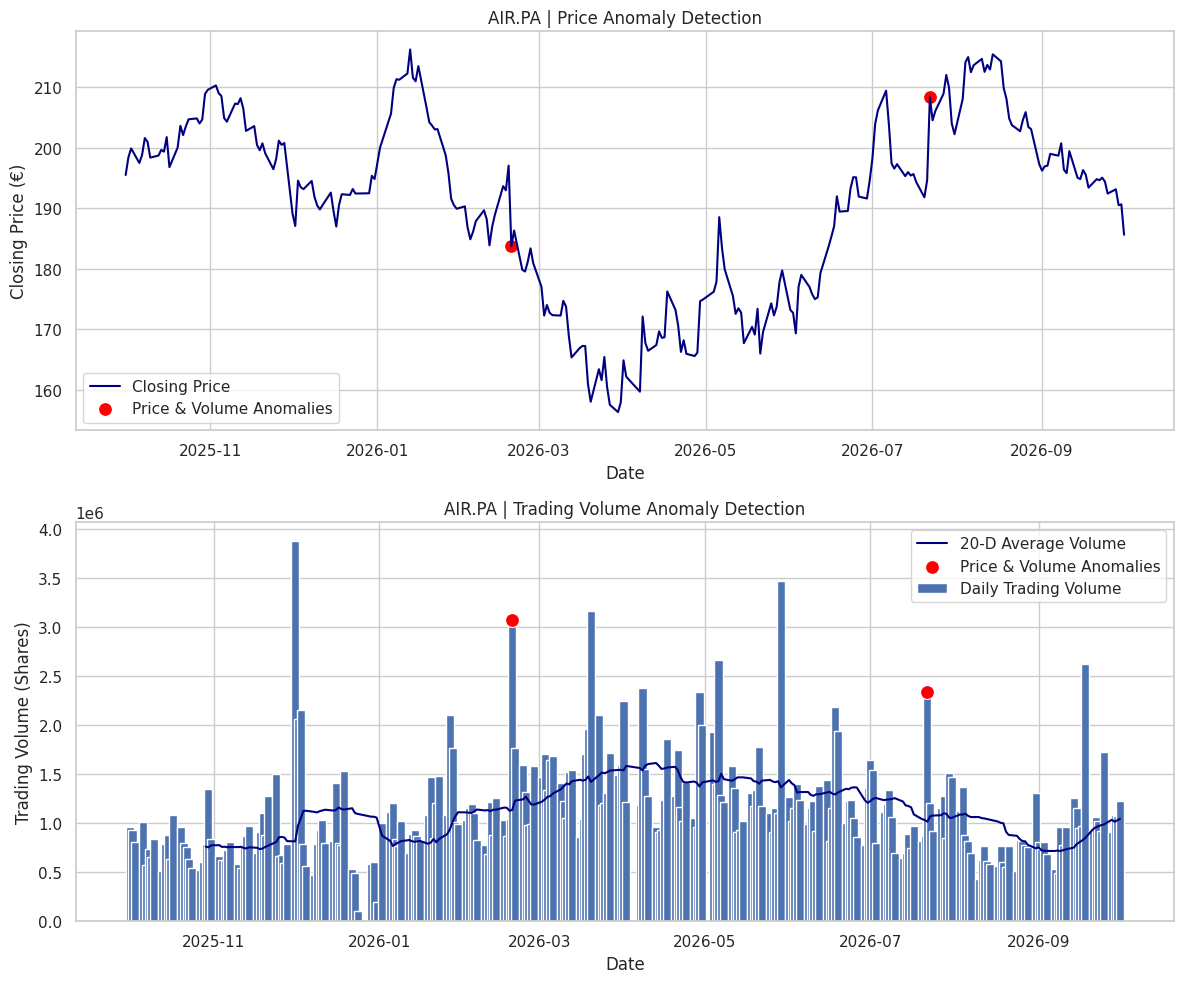

In [35]:
plot_market_anomalies('AIR.PA')

##8 - Limitations & Next Steps

1. Statistical Anomalies vs. Market Manipulation

    This model identifies unusual price movements and trading volumes relative to historical statistical benchmarks. However, these anomalies do not necessarily indicate market manipulation. They may result from earnings announcements, macroeconomic developments, geopolitical events, or company-specific news.

2. Historical data requirements

    The detection methodology requires sufficient historical observations to calculate rolling statistics. Price anomaly detection relies on a 60-day historical window, while volume analysis uses a 20-day moving window average. The current trading day is excluded from the calculation of its price thresholds to prevent look-ahead bias.

3. Detection limitations

    This model focuses on significant price movements and unusually high trading volumes. As combined alerts require both conditions to be satisfied, smaller or less visible irregularities may remain undetected. Consequently, the absence of an alert does not guarantee the absence of suspicious market activity.

4. Parameter sensitivity

    Detection results depend on the selected rolling windows and statistical thresholds. Shorter windows may respond more quickly to market changes but produce less stable estimates, while longer windows may provide greater stability at the expense of responsiveness. Further sensitivity testing would be necessary to evaluate the robustness of these parameters.